In [2]:
from tqdm import tqdm
import socket
import time
import datetime

import re

sockethost = "127.0.0.1"
socketport = 502

client_socket = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
client_socket.connect((sockethost, socketport))
client_socket.settimeout(2)  # 짧은 시간 설정

def newaresend(cmd: str):
    client_socket.send(cmd.encode("utf-8") + b"#\r\n#\r\n" )

def newarerecv():
    return client_socket.recv(20000).decode("utf-8")

def neware_start(subid = 1, chlid = 1, file = "pause test", 
                 savedir = "C:/NewareData", savename = "TEST",
                 backup = "C:/NewareData/backup", type = 0):
    newaresend('''<?xml version="1.0" encoding="UTF-8" ?> 
<bts version="1.0"> 
 <cmd>start</cmd> 
 <list count = "1"> 
  <start ip="192.168.1.2" devtype="25" devid="40" subdevid="{}" chlid="{}" >C:/NewareData/{}.xml</start> 
<backup backupdir="{}" remotedir="{}" filenametype="2" customfilename="{}" addtimewhenrepeat="0" filetype="{}" />
 </list> 
</bts>'''.format(subid, chlid, file, savedir, backup, savename, type))
    time.sleep(1)
    returnvalue = newarerecv()
    return returnvalue

def neware_continue(subid = 1, chlid = 1):
    newaresend('''<?xml version="1.0" encoding="UTF-8" ?> 
<bts version="1.0"> 
<cmd>continue</cmd> 
<list count = "1"> 
<continue ip="192.168.1.2" devtype="25" devid="40" subdevid="{}" chlid="{}" >true</continue> 
</list> 
</bts>'''.format(subid, chlid))
    time.sleep(1)
    returnvalue = newarerecv()
    return returnvalue

def neware_check(subid = 1, chlid = 1):
    newaresend('''<?xml version="1.0" encoding="UTF-8" ?> 
<bts version="1.0"> 
<cmd>getchlstatus</cmd> 
<list count = "1"> 
<status ip="192.168.1.2" devtype="25" devid="40" subdevid="{}" chlid="{}" >true</status> 
</list> 
</bts>'''.format(subid, chlid))
    time.sleep(1)
    returnvalue = newarerecv()
    if "finish" in returnvalue:
        return "finish"
    elif "working" in returnvalue:
        return "working"
    elif "stop" in returnvalue:
        return "stop"
    elif "pause" in returnvalue:
        return "pause"
    else:
        return returnvalue

def neware_checkall():
    newaresend('''<?xml version="1.0" encoding="UTF-8" ?><bts version="1.0"><cmd>getchlstatus</cmd><list count = "48">
<status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="8">true</status>
<status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="8">true</status>
<status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="8">true</status>
<status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="8">true</status>
<status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="8">true</status>
<status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="8">true</status>
</list></bts>''')
    time.sleep(1)
    returnlist = newarerecv()
    returnlist = re.findall(r'<status[^>]*>(\w+)</status>', returnlist)
    return returnlist

# ---- 자동 재연결 패치 ----
import functools

def neware_connect():
    global client_socket
    try:
        client_socket.close()
    except Exception:
        pass
    client_socket = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
    client_socket.connect((sockethost, socketport))
    client_socket.settimeout(2)

def _with_reconnect(func):
    if getattr(func, "_reconnect_wrapped", False):
        return func
    @functools.wraps(func)
    def wrapper(*args, **kwargs):
        attempt = 0
        while True:
            try:
                return func(*args, **kwargs)
            except (ConnectionResetError, ConnectionAbortedError,
                    BrokenPipeError, socket.timeout, OSError) as e:
                attempt += 1
                wait = min(3 * attempt, 30)
                print(f"[{datetime.datetime.now():%H:%M:%S}] Neware 연결 끊김: {e} → {wait}s 후 재접속 (시도 {attempt})")
                time.sleep(wait)
                try:
                    neware_connect()
                    print(f"[{datetime.datetime.now():%H:%M:%S}] Neware 재접속 성공, 이어서 진행")
                except Exception as ce:
                    print(f"[{datetime.datetime.now():%H:%M:%S}] 재접속 실패: {ce} (계속 재시도)")
    wrapper._reconnect_wrapped = True
    return wrapper

neware_check    = _with_reconnect(neware_check)
neware_continue = _with_reconnect(neware_continue)
neware_checkall = _with_reconnect(neware_checkall)

print("Neware 자동 재연결 패치 적용 완료")

Neware 자동 재연결 패치 적용 완료


## NEWARE TCP connect

In [3]:
# from tqdm import tqdm
# import socket
# import time
# import datetime

# import re

# sockethost = "127.0.0.1"
# socketport = 502

# client_socket = socket.socket(socket.AF_INET, socket.SOCK_STREAM)
# client_socket.connect((sockethost, socketport))
# client_socket.settimeout(2)  # 짧은 시간 설정

# # def newaresend(cmd: str, default_len = 4200):
# #     cmd_len = len(cmd)
# #     sendmsg = ' '*(default_len-cmd_len) + cmd
# #     client_socket.send(sendmsg.encode("utf-8"))

# def newaresend(cmd: str):
#     client_socket.send(cmd.encode("utf-8") + b"#\r\n#\r\n" )

# def newarerecv():
#     return client_socket.recv(20000).decode("utf-8")

# def neware_start(subid = 1, chlid = 1, file = "pause test", 
#                  savedir = "C:/NewareData", savename = "TEST",
#                  backup = "C:/NewareData/backup", type = 0):
#     """
#     subid: cycling device id (ex. 1 for 1-1 ~ 1-8 channel)
#     chlid: channel id (ex. 1 for 1-1, 2-1, ... channel)
#     file: cycling protocol file name (ex. pause test)
#     backup: backup data file save path
#     type: type of backup file (0: NDA, 1: excel)
#     """
#     newaresend('''<?xml version="1.0" encoding="UTF-8" ?> 
# <bts version="1.0"> 
#  <cmd>start</cmd> 
#  <list count = "1"> 
#   <start ip="192.168.1.2" devtype="25" devid="40" subdevid="{}" chlid="{}" >C:/NewareData/{}.xml</start> 
# <backup backupdir="{}" remotedir="{}" filenametype="2" customfilename="{}" addtimewhenrepeat="0" filetype="{}" />
#  </list> 
# </bts>'''.format(subid, chlid, file, savedir, backup, savename, type))
#     time.sleep(1)
#     returnvalue = newarerecv()
#     return returnvalue

# def neware_continue(subid = 1, chlid = 1):
#     """
#     subid: cycling device id (ex. 1 for 1-1 ~ 1-8 channel)
#     chlid: channel id (ex. 1 for 1-1, 2-1, ... channel)
#     """
#     newaresend('''<?xml version="1.0" encoding="UTF-8" ?> 
# <bts version="1.0"> 
# <cmd>continue</cmd> 
# <list count = "1"> 
# <continue ip="192.168.1.2" devtype="25" devid="40" subdevid="{}" chlid="{}" >true</continue> 
# </list> 
# </bts>'''.format(subid, chlid))
#     time.sleep(1)
#     returnvalue = newarerecv()
#     return returnvalue

# def neware_check(subid = 1, chlid = 1):
#     """
#     subid: cycling device id (ex. 1 for 1-1 ~ 1-8 channel)
#     chlid: channel id (ex. 1 for 1-1, 2-1, ... channel)
#     """
#     newaresend('''<?xml version="1.0" encoding="UTF-8" ?> 
# <bts version="1.0"> 
# <cmd>getchlstatus</cmd> 
# <list count = "1"> 
# <status ip="192.168.1.2" devtype="25" devid="40" subdevid="{}" chlid="{}" >true</status> 
# </list> 
# </bts>'''.format(subid, chlid))
#     time.sleep(1)
#     returnvalue = newarerecv()
#     if "finish" in returnvalue:
#         return "finish"
#     elif "working" in returnvalue:
#         return "working"
#     elif "stop" in returnvalue:
#         return "stop"
#     elif "pause" in returnvalue:
#         return "pause"
#     else:
#         return returnvalue

# def neware_checkall():
#     """
#     checking all channels

#     Return: list of channel status ex. [finish, finish, working, ...]
#     """
#     newaresend('''<?xml version="1.0" encoding="UTF-8" ?><bts version="1.0"><cmd>getchlstatus</cmd><list count = "48">
# <status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="1" chlid="8">true</status>
# <status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="2" chlid="8">true</status>
# <status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="3" chlid="8">true</status>
# <status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="4" chlid="8">true</status>
# <status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="5" chlid="8">true</status>
# <status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="1">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="2">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="3">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="4">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="5">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="6">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="7">true</status><status ip="192.168.1.2" devtype="25" devid="40" subdevid="6" chlid="8">true</status>
# </list></bts>''')
#     time.sleep(1)
#     returnlist = newarerecv()
#     returnlist = re.findall(r'<status[^>]*>(\w+)</status>', returnlist)
#     return returnlist

In [4]:
neware_check(6, 8)

'finish'

In [5]:
neware_checkall()

['working',
 'working',
 'finish',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'finish',
 'working',
 'working',
 'working',
 'working',
 'working',
 'working',
 'finish',
 'finish',
 'finish',
 'finish',
 'finish',
 'finish']

## PLC OPCUA connect

In [6]:
from opcua import Client, ua
opc_client = Client("opc.tcp://192.168.1.100:4840")
opc_client.connect()

def opc_send(node: str, value: bool or int or float or list):
    time.sleep(0.2)
    if type(value) == bool:
        opc_client.get_node("ns=4;s={}".format(node)).set_value(ua.DataValue(ua.Variant(value, ua.VariantType.Boolean)))
    elif type(value) == int:
        opc_client.get_node("ns=4;s={}".format(node)).set_value(ua.DataValue(ua.Variant(value, ua.VariantType.Int16)))
    elif type(value) == float:
        opc_client.get_node("ns=4;s={}".format(node)).set_value(ua.DataValue(ua.Variant(value, ua.VariantType.Double)))
    elif type(value) == list:
        # for our case, list is composed of float or string
        try:
            opc_client.get_node("ns=4;s={}".format(node)).set_value(ua.DataValue(ua.Variant(value, ua.VariantType.Float)))
        except:
            opc_client.get_node("ns=4;s={}".format(node)).set_value(ua.DataValue(ua.Variant(value, ua.VariantType.String)))
    time.sleep(0.2)

def opc_read(node: str):
    time.sleep(0.2)
    return opc_client.get_node("ns=4;s={}".format(node)).get_value()

def jigjob(job, index:int=0):
    """
    Job for the coincell jig
    job: Jig_Origin, Jig_Readypos, Jig_Insert, Jig_Retrieve, EIS_Insert, EIS_Retrieve
    * Jig: 0 ~ 47 (48 ch.) / EIS: 0 ~ 1 (2 ch.)
    index: position for Insert and Retrieve
    """
    opc_send("JOB", [job, str(index)])

Requested session timeout to be 3600000ms, got 60000ms instead


In [7]:
import pandas as pd

jig = pd.read_excel("C:/Users/HOME/Desktop/ethercat 지그 좌표.xlsx")
jig_position = jig.iloc[:, 1:7].values.tolist()
opc_send("Jigmove_csv", jig_position)
EIS_position = jig.iloc[0:2, 7:11].values.tolist()
opc_send("EISmove_csv", EIS_position)

In [8]:
opc_send("fbMotor1.Power.bPowerEnable", True)
opc_send("fbMotor2.Power.bPowerEnable", True)
opc_send("fbMotor3.Power.bPowerEnable", True)
opc_send("fbMotor4.Power.bPowerEnable", True)

opc_send("fbMotor1.MoveABS.rABSVel", 200.)
opc_send("fbMotor2.MoveABS.rABSVel", 200.)
opc_send("fbMotor3.MoveABS.rABSVel", 200.)
opc_send("fbMotor4.MoveABS.rABSVel", 200.)

opc_send("fbMotor1.MoveABS.rABSAccel", 200.)
opc_send("fbMotor2.MoveABS.rABSAccel", 200.)
opc_send("fbMotor3.MoveABS.rABSAccel", 200.)
opc_send("fbMotor4.MoveABS.rABSAccel", 200.)

opc_send("fbMotor1.MoveABS.rABSDecel", 200.)
opc_send("fbMotor2.MoveABS.rABSDecel", 200.)
opc_send("fbMotor3.MoveABS.rABSDecel", 200.)
opc_send("fbMotor4.MoveABS.rABSDecel", 200.)

## Biologics connect

In [9]:
import sys
sys.path.append("C:/Users/HOME/easy-biologic/src")

import easy_biologic as ebl
import easy_biologic.base_programs as blp

bl = ebl.BiologicDevice('192.168.1.128')
bl.connect()

In [10]:
# eis 용 parameter
params = {
    'voltage': -3.56, # initial potential [Volts] 은 이후 ocv 찍은걸로 반영
    'amplitude_voltage': 0.01, # Sinus amplitude [Volts]
    'initial_frequency': 200000, # [Hz]
    'final_frequency': 0.1,# [Hz]
    'frequency_number': 39, #39
    'duration': 0,
    'vs_initial': False, #default:False
    'repeat': 2, #default:1
    #'time_interval': 2, #default:1
    #'current_interval': 0.5, #default:0.001
    #'sweep': 1.0, #default:'log'
    #'correction': 1.0, #default:F}alse
    'wait': 0.1, #default:0
    } 

# ocv 측정용 parameter
params_ocv = {'time':2, 'time_interval':1}

## Check Status and automate EIS (자동 진행)

In [11]:
# === EIS OCV 양수 감지 시 SLACK 알람 활성화 (sodium_auto.py 참고) ===
# notify_done(message=...) 만 있으면 슬랙 전송 가능
import sys, importlib
sys.path.insert(0, r"C:\Users\HOME\Desktop\YOH\python codes\ALBATROSS_GUI")
import albatross_step_check
importlib.reload(albatross_step_check)          # 캐시 무시하고 파일 다시 읽기
from albatross_step_check import notify_done
print("notify_done 로드됨:", "notify_done" in dir(albatross_step_check))

notify_done 로드됨: True


In [12]:
###################      EIS 채널 1만 사용가능!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!

eis_channel = 1

# === 슬랙 알람 모듈 로드 (실패하면 알람만 비활성, 자동화는 그대로 진행) ===
import sys, importlib
sys.path.insert(0, r"C:\Users\HOME\Desktop\YOH\python codes\ALBATROSS_GUI")
try:
    import albatross_step_check
    importlib.reload(albatross_step_check)          # 캐시 무시하고 파일 다시 읽기
    from albatross_step_check import notify_done
    print("notify_done 로드됨")
except Exception as e:
    notify_done = None
    print("notify_done 로드 실패 -> 슬랙 알람 비활성:", e)

def ocv_eis(save_path, channel = eis_channel, slack = True, cell_label = None):
    '''
    ocv 측정 이후 eis 측정하는 함수
    eis 초기 전압을 현재 셀 ocv 로 세팅하기 위해 ocv 측정 필수

    save_path: eis 를 저장할 위치 (ocv 는 따로 저장하지 않음)
    channel: 사용할 eis 채널 위치 (left = 0, right = 1)
    slack: OCV 양수일 때 슬랙 알람 + Enter 대기 여부
    cell_label: 알람 메시지에 표시할 셀 이름 (예: "5(1-6)")
    '''
    ocv = blp.OCV(bl, params_ocv, channels = [channel])
    ocv.run()
    voc = {
        ch: [datum.voltage for datum in data]
        for ch, data in ocv.data.items()
    }
    voc = {
        ch: sum(ch_voc) / len(ch_voc)
        for ch, ch_voc in voc.items()
    }

    voc_value = list(voc.values())[0]
    params['voltage'] = voc_value
    print("voc:", voc)

    # === OCV 양수 감지 -> 슬랙 알람 후 엔터 대기 ===
    # 정상 셀 OCV 는 음수(약 -2.6 ~ -3.6 V). 양수면 셀 이상/접촉 불량 의심.
    if slack and voc_value > 0:
        label = cell_label if cell_label is not None else save_path
        msg = ("[EIS] OCV 양수 감지! {} -> OCV = {:+.4f} V\n"
               "확인 후 Jupyter 에서 Enter 를 눌러야 자동화가 계속 진행됩니다.").format(label, voc_value)
        print(msg)
        if notify_done is not None:
            try:
                notify_done(message=msg)
            except Exception as e:
                print("슬랙 알람 전송 실패:", e)
        # 연구자가 셀 확인 후 Enter 를 누를 때까지 전체 자동화 정지
        input(">>> OCV 양수({:+.4f} V) [{}] 확인 후 Enter 를 누르면 계속 진행합니다... ".format(voc_value, label))

    peis = blp.PEIS(bl, params, channels = [channel])
    peis.run()
    peis.save_data(save_path)
    
def cycle_server(directory = "C://EIS", check_ch: list = range(48), eis_jig = eis_channel, eisauto = True, slack = True):
    '''
    Neware 의 채널 상태가 pause 인 경우 해당 채널의 셀을 EIS 로 이송

    check_ch: 실시간으로 체크할 Neware 채널
    eis_jig: 사용할 eis jig (0 왼쪽, 1 오른쪽)
    eisauto: python EIS automation 사용 여부
    slack: slack 알람 여부
    '''
    # sub id 및 chl id 로 변환
    checklist = []
    for i in check_ch:
        sub_id = i//8+1
        chl_id = i%8+1
        temp = [sub_id, chl_id]
        checklist.append(temp)
    
    while True:
        time.sleep(1)
        for n, i in enumerate(checklist):
            # pause 상태의 채널 확인
            if neware_check(i[0], i[1]) == 'pause':
                print("Check pause status {}-{}".format(i[0], i[1]))
                
                # pause 셀을 EIS 채널로 이송
                jigjob("Jig_Retrieve", check_ch[n])
                jigjob("EIS_Insert", eis_jig)
                
                # 실제 해당 채널에서 Retrieve 가 진행되면 loop 해제
                while True:
                    time.sleep(1)
                    gantry_check = opc_read("DataJig.Gantry")
                    if gantry_check[0] == "Jig_Retrieve" and gantry_check[1] == str(check_ch[n]):
                        break

                # EIS_Insert 가 실행되면 75초 뒤 EIS test 실행
                while True:
                    time.sleep(1)
                    gantry_check = opc_read("DataJig.Gantry")
                    if gantry_check[0] == "EIS_Insert" and gantry_check[1] == str(eis_jig):
                        break
                time.sleep(15) # 원점으로부터 EIS 채널까지 가는데 걸리는 시간
                    
                # 파일 이름 생성
                # 같은 날에 찍으면 파일이 덧씌워짐
                # 따라서 파일 이름을 250916162020 처럼 시 분 초 기록도 넣어버림...
                today = datetime.datetime.now().strftime("%y%m%d%H%M%S")
                save_path = "{}/{}_{}({}-{}).csv".format(directory, today, check_ch[n], i[0], i[1])
                
                # python EIS 실행
                print("Start OCV/EIS TEST")
                ocv_eis(save_path, channel=eis_jig, slack=slack,
                        cell_label="{}({}-{})".format(check_ch[n], i[0], i[1]))
                
                # 셀 원래 채널로
                jigjob("EIS_Retrieve", eis_jig)
                jigjob("Jig_Insert", check_ch[n])

                # 셀이 원래 채널로 돌아가면 pause 상태 해제
                while True:
                    time.sleep(1)
                    gantry_check = opc_read("DataJig.Gantry")
                    if gantry_check[0] == "Jig_Insert" and gantry_check[1] == str(check_ch[n]):
                        break

                while True:
                    time.sleep(1)
                    gantry_check = opc_read("DataJig.Gantry")
                    if gantry_check[0] != "Jig_Insert" or gantry_check[1] != str(check_ch[n]):
                        break
                        
                neware_continue(i[0], i[1])

notify_done 로드됨


In [ ]:
#### OCV 체크하는 곳 ####

# ocv_eis("./test/test.csv", 1)

# Run

In [ ]:
# EIS 확인 및 측정 자동화 시작!
# 조립 시작하면 꺼야 함! (1)
#!!!!!!!!!!!!해당 라운드로 바꿔주세요!!!!!!!!!!!!!!!!!
round = 8

import sys, importlib
sys.path.insert(0, r"C:\Users\HOME\Desktop\YOH\python codes\ALBATROSS_GUI")
import albatross_step_check
importlib.reload(albatross_step_check)          # 캐시 무시하고 파일 다시 읽기
from albatross_step_check import notify_done
print("notify_done 로드됨:", "notify_done" in dir(albatross_step_check))

import os

today = datetime.datetime.now().strftime("%y%m%d")
savedir = f"C:/Users/HOME/Desktop/KAIST/LGES/Sodium_2year/EIS/EIS_{round}_{today}/"

eis_savedir = savedir + "PEIS/"
os.makedirs(savedir, exist_ok=True)
os.makedirs(eis_savedir, exist_ok=True)

cycle_server(directory = eis_savedir, check_ch = range(48))

notify_done 로드됨: True
Check pause status 2-2
Start OCV/EIS TEST
voc: {1: -3.6769278049468994}
Check pause status 2-2
Start OCV/EIS TEST
voc: {1: -3.7919090588887534}
Check pause status 2-2
Start OCV/EIS TEST
voc: {1: -3.7369911670684814}
Check pause status 2-2
Start OCV/EIS TEST
voc: {1: -3.315704584121704}
Check pause status 5-8
Start OCV/EIS TEST
voc: {1: -3.7226845423380532}
Check pause status 2-2
Start OCV/EIS TEST
voc: {1: -2.809060573577881}
Check pause status 5-8
Start OCV/EIS TEST
voc: {1: -3.825347979863485}
Check pause status 2-2
Start OCV/EIS TEST
voc: {1: -2.533040682474772}
Check pause status 5-8
Start OCV/EIS TEST
voc: {1: -3.3543774286905923}
Check pause status 2-2
Start OCV/EIS TEST
voc: {1: -2.4411601225535073}
Check pause status 5-8
Start OCV/EIS TEST
voc: {1: -2.6337106227874756}
Check pause status 2-2
Start OCV/EIS TEST
voc: {1: -2.4072229067484536}
Check pause status 5-8
Start OCV/EIS TEST
voc: {1: -2.4603259563446045}
Check pause status 2-2
Start OCV/EIS TEST
voc:

# 충방전 실행 자동화

In [9]:
protocol = "C:/NewareData/251121_MTI_NCM811_1C50cycEIS.xml"# 사용할 충방전 프로토콜
savedir = 'C:/NewareData/251125_NCM811_1C50cycEIS/' # 저장 공간
backup = 'C:/NewareData/251125_NCM811_1C50cycEIS/remote_dir/' # 백업 공간

In [10]:
skip_list = [0, 35, 43] # 동작 안되는 세 채널 제외

In [11]:
# 충방전기 시작 (실제 시작 시간과 약간 다름!)
for i in range(10, 16):
    if i in skip_list:
        continue
    sub_id = i//8+1
    chl_id = i%8+1
    now = datetime.datetime.now().strftime("%y%m%d")
    neware_start(
        sub_id, chl_id, protocol, 
        savedir, now+"_{}-{}".format(sub_id, chl_id), 
        backup
    )

# 디버깅

In [7]:
neware_ch_status = []
for i in range(6):
    for j in range(8):
        neware_ch_status.append(neware_check(i+1, j+1))

In [ ]:
neware_ch_status

In [16]:
time.sleep(10)
for i in range(8, 48):
    jigjob("Jig_Retrieve", i)

In [16]:
jigjob("Jig_Retrieve", 1)
jigjob("EIS_Insert", 0)

In [33]:
# jigjob("EIS_Retrieve", 1)
jigjob("Jig_Insert", 3)

In [21]:
jigjob("Jig_Readypos")

In [149]:
jigjob("Jig_Insert", 1)

In [140]:
jigjob("Jig_Retrieve",1)

In [466]:
opc_send("fbMotor2.MoveABS.rABSPos", 333.)

In [467]:
opc_send("fbMotor2.MoveABS.bABSEnable", True)

In [475]:
import pandas as pd

jig = pd.read_excel("C:/Users/HOME/Desktop/ethercat 지그 좌표.xlsx")
jig_position = jig.iloc[:, 1:7].values.tolist()
opc_send("Jigmove_csv", jig_position)
EIS_position = jig.iloc[0:2, 7:11].values.tolist()
opc_send("EISmove_csv", EIS_position)

In [476]:
jigjob("Jig_Insert", 40)

In [477]:
jigjob("Jig_Retrieve", 40)

In [458]:
jigjob("EIS_Retrieve", 0)

In [485]:
idx = 47

for i in range(5):
    jigjob("Jig_Insert", idx)
    time.sleep(0.1)
    jigjob("Jig_Retrieve", idx)
    time.sleep(0.1)

In [14]:
def Zcal(filename):
    df = pd.read_csv(filename, header = 1)
    modulus = df["Impedance modulus"]
    phase = df["Impedance phase"]
    Z = modulus * np.exp(1j * phase)
    Z = np.array(Z)
    return Z

In [31]:
def nyquist(Z_list, eisfilelist = None, xlim = [0, 160], ylim = [0, 160], label = False):
    plt.figure(figsize = (6, 6))

    for n, i in enumerate(Z_list):
        if eisfilelist == None:
            plt.scatter(i.real, -i.imag, s = 10)
        # else:
        #     channel = extract_key(eisfilelist[n])
        # plt.scatter(i.real, -i.imag, s = 10, label = "{}-{}".format(channel[0], channel[1]))
        plt.scatter(i.real, -i.imag, s = 10)
        

    if label:
        plt.legend()
        plt.xlim(xlim)
        plt.ylim(ylim)
        plt.grid()
        # plt.show()

In [24]:
import numpy as np
import matplotlib.pyplot as plt

In [36]:
zcal = Zcal("C:/EIS/260310193557_43(6-4).csv")

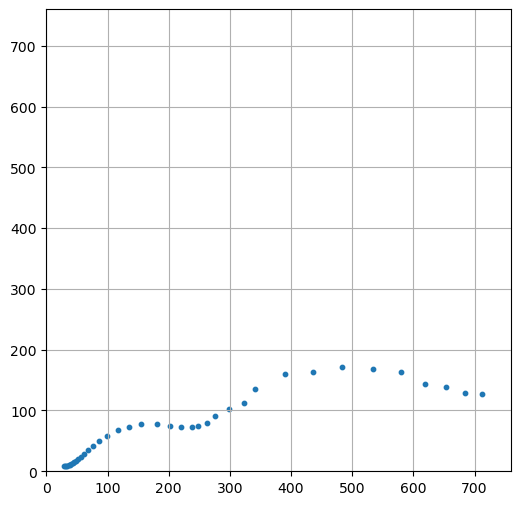

In [37]:
nyquist([zcal], [0])
plt.xlim([0, 760])
plt.ylim([0, 760])
plt.grid()

In [19]:
save_path = "C://EIS/250711_1(1-2)_OCV0.csv"

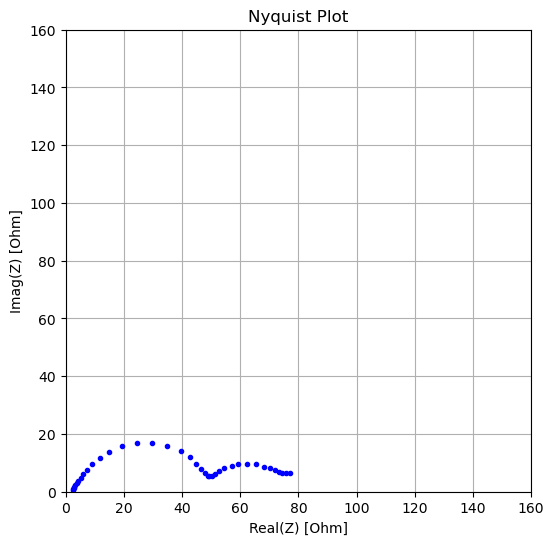

In [12]:
nyquist("250719_7(1-8)")

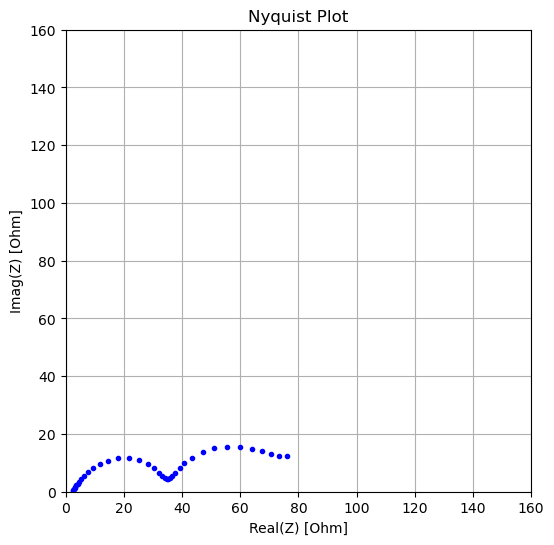

In [18]:
nyquist("250719_1(1-2)")

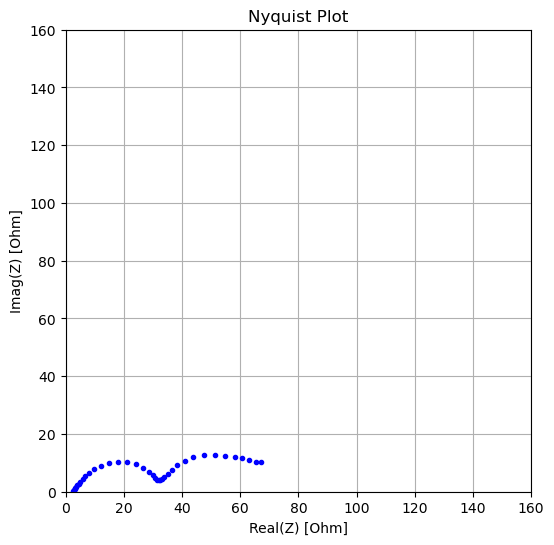

In [27]:
nyquist("250719_0(1-1)")

In [ ]:
nyquist("250719_2(1-3)")

## 연결 종료 
셀 조립하면 꺼야함! 2

In [26]:
bl.disconnect()

RuntimeError: Device is not connected.

In [27]:
client_socket.close()

In [28]:
opc_client.disconnect()

OSError: [WinError 10038] 소켓 이외의 개체에 작업을 시도했습니다